# 18 · Executive Portfolio Findings (`18_portfolio_findings.py`)

Script `18_portfolio_findings.py` pulls all finished Module 2 marts together into the final credit-risk executive report (`18_portfolio_findings.md`) without scanning raw monthly rows. Here we mirror that synthesis step strictly read-only—computing the core portfolio KPI scorecard directly from `module2_sample.duckdb`, comparing our findings against the saved markdown report path, and plotting era-by-era default rates.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Executive Findings Rollup Across All Module 2 Marts</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Default & LGD Marts</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">DR history & credit-exit severity</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">IV, Mix & PSI Marts</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">Top risk drivers & drift</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Findings Scorecard</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">Headline executive KPIs</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Saved Report Match</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">18_portfolio_findings.md</text>
</svg></div>

First we import `18_portfolio_findings` only to inspect definitions safely (never invoking disk writes), attach `module2_sample.duckdb` read-only, and compute the headline Module 2 scorecard across all core marts.

In [1]:
# Load standard libraries and import 18_portfolio_findings read-only
# Configure BytesIO display helpers and attach module2_sample.duckdb strictly READ_ONLY
import importlib
import io
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and insert 02_portfolio_analytics/scripts onto sys.path
# Walk upward until reaching residential_mortgage/, then expose Module 2 script definitions
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

pf_mod = importlib.import_module("18_portfolio_findings")
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
FIXED_MD = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/18_portfolio_findings/18_portfolio_findings.md"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Query headline KPIs spanning volume, defaults, long-run DR, Vasicek rho, and realized LGD
# Aggregate exact summary metrics from saved marts and check saved markdown report presence
total_loans = con.execute("SELECT count(*) FROM m2.loan_lifetime_mart").fetchone()[0]
total_defs = con.execute("SELECT count(*) FROM m2.default_events_mart").fetchone()[0]
lra_dr, peak_dr = con.execute("""
    SELECT 100.0 * avg(default_rate_count), 100.0 * max(default_rate_count)
    FROM m2.default_rate_history_mart
    WHERE series_group = 'whole_book' AND window_complete
""").fetchone()
rho_wb = con.execute("SELECT implied_rho FROM m2.implied_correlation_mart WHERE segment = 'all'").fetchone()[0]
exit_lgd = con.execute("""
    SELECT 100.0 * sum(CAST(net_loss AS DOUBLE)) / NULLIF(sum(CAST(balance_at_default AS DOUBLE)), 0)
    FROM m2.default_outcomes_mart WHERE end_reason = 'credit exit'
""").fetchone()[0]

print(f"Saved report present: {FIXED_MD.exists()} ({FIXED_MD.stat().st_size:,} bytes)")
pd.DataFrame([
    {"Metric": "Sample Loans Audited", "Value": f"{total_loans:,}"},
    {"Metric": "Regulatory Default Events", "Value": f"{total_defs:,}"},
    {"Metric": "Long-Run Average 12m DR (%)", "Value": f"{lra_dr:.2f}%"},
    {"Metric": "Peak 12m DR (%)", "Value": f"{peak_dr:.2f}%"},
    {"Metric": "Vasicek Implied Asset Correlation (Whole Book)", "Value": f"{rho_wb:.4f}"},
    {"Metric": "Realized Credit-Exit LGD (%)", "Value": f"{exit_lgd:.2f}%"},
])

Saved report present: True (6,475 bytes)


,Metric,Value
0,Sample Loans Audited,117
1,Regulatory Default Events,793
2,Long-Run Average 12m DR (%),0.95%
3,Peak 12m DR (%),3.39%
4,Vasicek Implied Asset Correlation (Whole Book),0.0553
5,Realized Credit-Exit LGD (%),28.21%


Next we plot the era-by-era comparison of mean annualized default rates across all five macroeconomic regimes directly from `m2.portfolio_rates_quarterly_mart`.

,era,mean_ann_dr_pct,peak_ann_dr_pct
0,2000-2006 build-up,0.41,1.69
1,2007-2010 crisis,1.98,4.81
2,2011-2019 recovery,0.90,2.76
3,2020-2021 COVID,1.65,6.30
4,2022-2025 recent,0.54,0.94


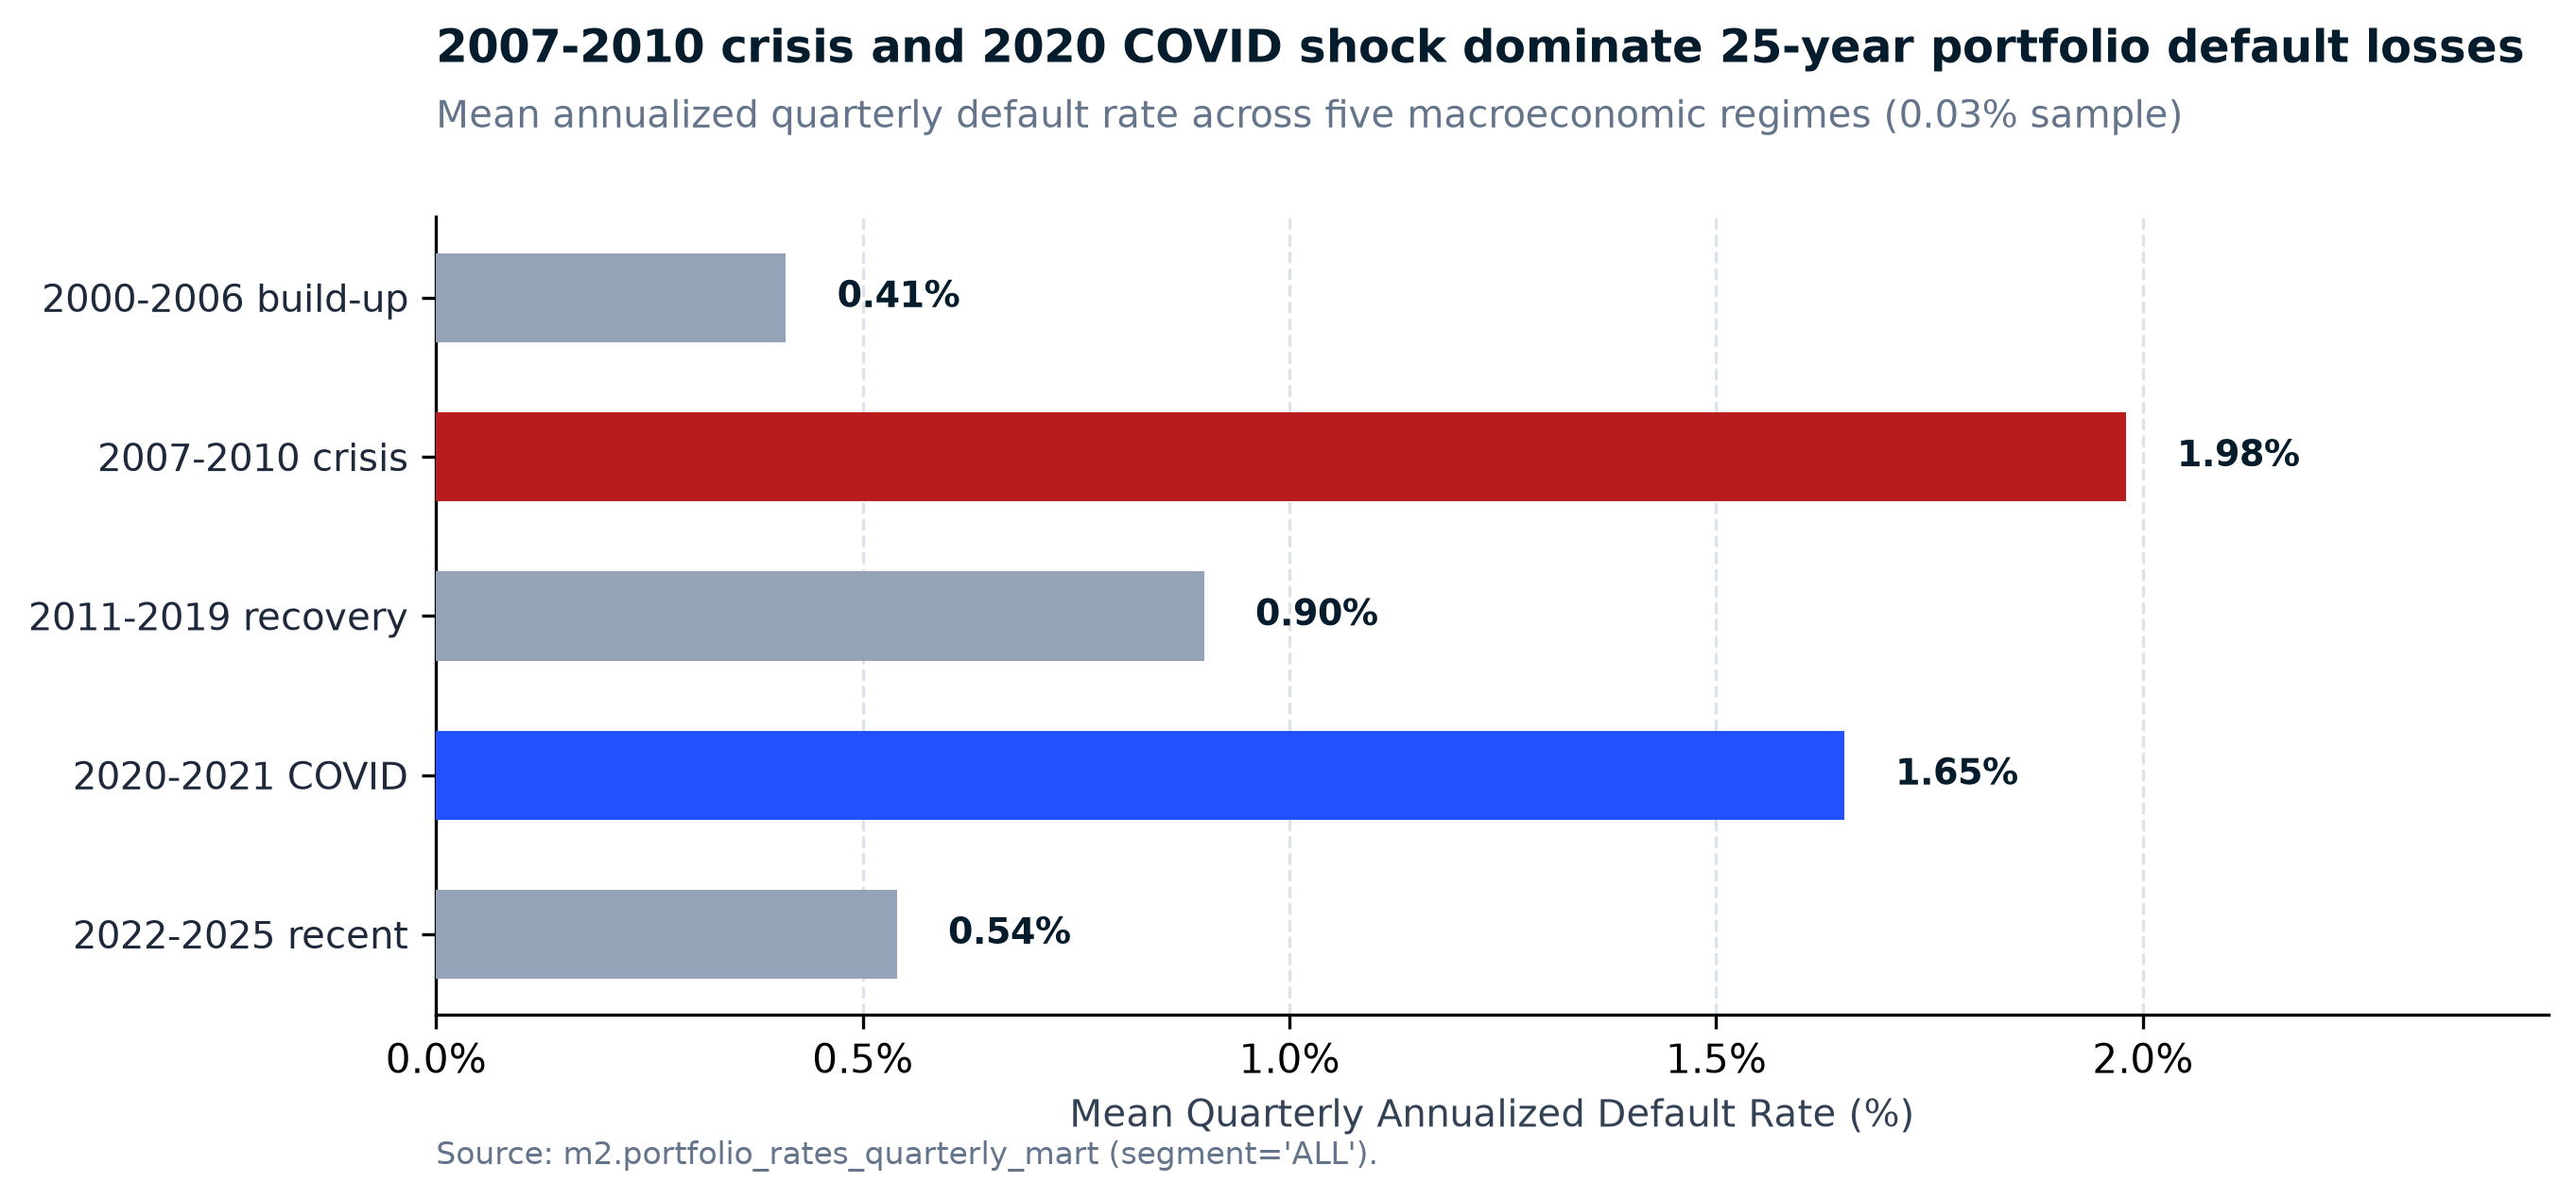

In [2]:
# Summarize and chart mean annualized default rate across the five macroeconomic eras
# Group whole-book quarterly rates by era and plot horizontal benchmark bars at 300 dpi
era_df = con.execute("""
    SELECT CASE WHEN year(quarter_date) <= 2006 THEN '2000-2006 build-up'
                WHEN year(quarter_date) <= 2010 THEN '2007-2010 crisis'
                WHEN year(quarter_date) <= 2019 THEN '2011-2019 recovery'
                WHEN year(quarter_date) <= 2021 THEN '2020-2021 COVID'
                ELSE '2022-2025 recent' END AS era,
           round(100.0 * avg(default_rate_ann), 2) AS mean_ann_dr_pct,
           round(100.0 * max(default_rate_ann), 2) AS peak_ann_dr_pct
    FROM m2.portfolio_rates_quarterly_mart
    WHERE segment = 'ALL'
    GROUP BY 1
    ORDER BY min(quarter_date)
""").fetchdf()
display(era_df)

fig, ax = plt.subplots(figsize=(9.8, 4.2), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
y = range(len(era_df))
colors = ["#94A3B8" if "crisis" not in e and "COVID" not in e else ("#B91C1C" if "crisis" in e else "#2251FF") for e in era_df["era"]]
bars = ax.barh(y, era_df["mean_ann_dr_pct"], color=colors, height=0.56, zorder=3)
for bar, val in zip(bars, era_df["mean_ann_dr_pct"]):
    ax.text(val + 0.06, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontsize=9, fontweight="bold", color="#051C2C")
ax.set_yticks(list(y))
ax.set_yticklabels(era_df["era"], fontsize=9.5, color="#1E293B")
ax.invert_yaxis()
ax.set_xlim(0, era_df["mean_ann_dr_pct"].max() * 1.25)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Mean Quarterly Annualized Default Rate (%)", fontsize=9.5, color="#334155")
fig.text(0.20, 0.94, "2007-2010 crisis and 2020 COVID shock dominate 25-year portfolio default losses", fontsize=11.5, fontweight="bold", color="#051C2C")
fig.text(0.20, 0.885, "Mean annualized quarterly default rate across five macroeconomic regimes (0.03% sample)", fontsize=9.5, color="#64748B")
fig.text(0.20, 0.015, "Source: m2.portfolio_rates_quarterly_mart (segment='ALL').", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.20, right=0.96, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()